In [1]:
import numpy as np
import FBA_ode

In [2]:
# constants
k = np.zeros(31)

k[0] = 1.0e-5  # Permeability constant (plasma membrane) (cm/s)
k[1] = 1.1e-7  # Intracellular peroxide production (M/s)
k[2] = 2.1e7  # GPx_red reacting with H2O2in (M-1*s-1)
k[3] = 4e4  # GPx_ox reacting with GSH (M-1*s-1)
k[4] = 1e7  # GPx-SSG reacting with GSH (M-1*s-1)
k[5] = 3.4e7  # Catalase reacts with H2O2 inside peroxisome (M-1*s-1)
k[6] = 5.7e-5  # Km of NADP+ (M)
k[7] = 4e7  # Peroxiredoxin is oxidized by H2O2 (M-1*s-1)
k[8] = 7.2e4  # Oxidized peroxiredoxin is over-oxidized by H2O2 (M-1*s-1)
k[9] = 3e-3  # Reduction of overoxidized Prx by Srx enzyme (s-1)
k[10] = 15  # Self-catalyzed disulfide formation of Prx-SS from Prx-SOH (s-1)
k[11] = 2.1e6  # Peroxiredoxin is reduced by Thioredoxin (M-1*s-1)
k[12] = 7.4e-05  # Auto-oxidation of GSH (s-1)
k[13] = 1e4  # Protein monothiol oxidized by H2O2 (M-1*s-1)
k[14] = 1.2e5  # Oxidized Protein monothiol glutathionylated by GSH (M-1*s-1)
k[15] = 9.1e4  # Grx-SH de-glutathionylates Protein-SSG (M-1*s-1)
k[16] = 3.7e4  # GSH de-glutathionylates Grx-SSG (M-1*s-1)
k[17] = 5e5  # Protein dithiol oxidized by H2O2 (M-1*s-1)
k[18] = 1e5  # Protein disulfide reduced by Trx (M-1*s-1)
k[19] = 3.2e6  # GSSG reduced by GR (M-1*s-1)
k[20] = 2e7  # Oxidized Thioredoxin reduced by TrxR (M-1*s-1)
k[21] = 3.75e-04  # Production of NADPH by G6P-DH (M/s)
k[22] = 3e-3  # Permeability constant (peroxisomal membrane) (cm/s)
k[23] = 4.1e-7  # GSH synthesis (M/s)
k[24] = 1.2e-8  # GSSG efflux (M/s)
k[25] = 1.2e-7  # GSH + GSSG efflux (M/s)
k[26] = 7.45e-10  # Trx_SH efflux (M/s)
k[27] = 6.97e-10  # Trx_SH synthesis (M/s)
k[28] = 0#1e-7 # nox generation of superoxide ()
k[29] = 0#4e9 # superoxide dismutase reduction and oxidation by superoxide (M-1*s-1)
k[30] = 0#1e-4 # intracellular superoxide production (M/s)

print(k)

[1.00e-05 1.10e-07 2.10e+07 4.00e+04 1.00e+07 3.40e+07 5.70e-05 4.00e+07
 7.20e+04 3.00e-03 1.50e+01 2.10e+06 7.40e-05 1.00e+04 1.20e+05 9.10e+04
 3.70e+04 5.00e+05 1.00e+05 3.20e+06 2.00e+07 3.75e-04 3.00e-03 4.10e-07
 1.20e-08 1.20e-07 7.45e-10 6.97e-10 0.00e+00 0.00e+00 0.00e+00]


In [35]:
# initial conditions

# % Defining initial Conditions (Concentrations in uM = uMoles/Liter)
# % Defining the array, x0, that will house initial concentrations
x0 = np.zeros(28)  # Defining the array, x0, that will house initial concentrations
# Cytoplasm
x0[0] = 4e-7#3.994175567263817e-07 #1e-4  # H2O2media 
x0[1] = 1e-9 #8.024315925651471e-10  # H2O2cytosol

x0[2] = 5e-5  # GPXr 
x0[3] = 1e-14  # GPXo 
x0[4] = 1e-14  # GPX-SG 

x0[5] = 3.68e-4  # GSH 
x0[6] = 1.78e-6  # GSSG 

x0[7] = 9e-7  # Catalase 
x0[8] = 1.0e-10  # H2O2peroxisome 

x0[9] = 1.92e-5  # Prx-SH  
x0[10] = 1e-14  # Prx-SOH 
x0[11] = 1e-14  # Prx-SOOH 
x0[12] = x0[9] * (0.5 / 100)  # Prx-SS 

x0[13] = 4.27e-7  # Trx1-SH 
x0[14] = 7.54e-8  # Trx1-SS 

x0[15] = 1.22e-4  # Pr-SH 
x0[16] = x0[15] * (0.5 / 100)  # Pr-SOH
x0[17] = x0[15] * (0.5 / 100)  # Pr-SSG 

x0[18] = 1.20e-6  # Grx-SH 
x0[19] = x0[18] * (0.5 / 100)  # Grx-SSG 

x0[20] = 1.09e-3  # Pr-(SH)2  
x0[21] = x0[20] * (0.5 / 100)  # Pr-SS

x0[22] = 3.0e-5  # NADPH 
x0[23] = 3.0e-7  # NADP+

x0[24] = 0 # superoxide media
x0[25] = 0 # superoxide cytosol

x0[26] = 0#1e-14 # superoxide dismutase reduced
x0[27] = 0#2e-5 # superoxide dismutase oxidized

In [16]:
import numpy as np
from scipy.integrate import odeint

def model(x, t, k):
    dxdt = np.zeros_like(x)
    dxdt[0] = k[0] * (x[1] - x[0]) * 10e-3 * 1.02e-5 * (1e9)

    dxdt[1] = (((k[0] * x[0] * 10e-3 * 1.02e-5) / (9.16e-13))
               - ((k[0] * x[1] * 10e-3 * 1.02e-5) / (9.16e-13))
               - 2 * (k[22] * x[1] * 10e-3 * 2.98e-9) / (1.53e-14)
               - k[2] * x[2] * (x[1] - x0[1])
               - k[5] * x[7] * (x[1] - x0[1])
               - k[7] * x[9] * (x[1] - x0[1])
               - k[8] * x[10] * (x[1] - x0[1])
               - k[13] * x[15] * (x[1] - x0[1])
               - k[17] * x[20] * (x[1] - x0[1])
               + k[1]
               + k[29] * x[25] * x[27]                                      # superoxide dismutase reduction and oxidation by superoxide
               )
    
    dxdt[2] = - k[2] * x[2] * (x[1] - x0[1]) + k[4] * (x[4] - x0[4]) * x[5]
    dxdt[3] = k[2] * x[2] * (x[1] - x0[1]) - k[3] * (x[3] - x0[3]) * x[5]
    dxdt[4] = k[3] * (x[3] - x0[3]) * x[5] - k[4] * (x[4] - x0[4]) * x[5]
    dxdt[5] = (- k[3] * (x[3] - x0[3]) * x[5]
               - k[4] * (x[4] - x0[4]) * x[5]
               - 2 * k[12] * x[5]
               - k[14] * (x[16] - x0[16]) * x[5]
               - k[16] * (x[19] - x0[19]) * x[5]
               + 2 * k[19] * (x[6] - x0[6]) * x[22]
               + k[23] 
               - k[25])
    dxdt[6] = (k[4] * (x[4] - x0[4]) * x[5] + k[12] * x[5] +
               k[16] * (x[19] - x0[19]) * x[5] - k[19] * (x[6] - x0[6]) * x[22] -
               k[24] - k[25])
    dxdt[7] = 0
    dxdt[8] = (k[22] * x[1] * 10e-3 * 2.98e-9) / (1.53e-14) - k[5] * x[7] * (x[8] - x0[8])
    dxdt[9] = - k[7] * x[9] * (x[1] - x0[1]) + k[11] * (x[12] - x0[12]) * x[13]
    dxdt[10] = (k[7] * x[9] * (x[1] - x0[1]) - k[8] * x[10] * (x[1] - x0[1]) +
                k[9] * (x[11] - x0[11]) - k[10] * x[10])
    dxdt[11] = k[8] * x[10] * (x[1] - x0[1]) - k[9] * (x[11] - x0[11])
    dxdt[12] = k[10] * x[10] - k[11] * (x[12] - x0[12]) * x[13]
    dxdt[13] = (- k[11] * (x[12] - x0[12]) * x[13] 
                - k[18] * (x[21] - x0[21]) * x[13] 
                + k[20] * (x[14] - x0[14]) * x[22] 
                - k[26] 
                + k[27])
    dxdt[14] = (k[11] * (x[12] - x0[12]) * x[13] + k[18] * (x[21] - x0[21]) * x[13] -
                k[20] * (x[14] - x0[14]) * x[22])
    
    dxdt[15] = (- k[13] * x[15] * (x[1] - x0[1]) 
                + k[15] * x[18] * (x[17] - x0[17]))
    
    dxdt[16] = k[13] * x[15] * (x[1] - x0[1]) - k[14] * (x[16] - x0[16]) * x[5]
    dxdt[17] = k[14] * (x[16] - x0[16]) * x[5] - k[15] * x[18] * (x[17] - x0[17])
    dxdt[18] = k[16] * (x[19] - x0[19]) * x[5] - k[15] * x[18] * (x[17] - x0[17])
    dxdt[19] = k[15] * x[18] * (x[17] - x0[17]) - k[16] * (x[19] - x0[19]) * x[5]
    dxdt[20] = - k[17] * x[20] * (x[1] - x0[1]) + k[18] * (x[21] - x0[21]) * x[13]
    dxdt[21] = k[17] * x[20] * (x[1] - x0[1]) - k[18] * (x[21] - x0[21]) * x[13]

    dxdt[22] = (- k[19] * (x[6] - x0[6]) * x[22] 
                - k[20] * (x[14] - x0[14]) * x[22] 
                - k[28] * x[22]                                         # nox generation of superoxide
                + k[21] * (x[23] - x0[23]) / (k[6] + x[23]))
    
    dxdt[23] = (k[19] * (x[6] - x0[6]) * x[22] 
                + k[20] * (x[14] - x0[14]) * x[22] 
                + k[28] * x[22]                                         # nox generation of superoxide and nadp+
                - k[21] * (x[23] - x0[23]) / (k[6] + x[23]))
    
    dxdt[24] = (k[0] * (x[25] - x[24]) * 10e-3 * 1.02e-5 * (1e9)               # superoxide media
                + k[28] * x[22])
    
    dxdt[25] = (((k[0] * x[24] * 10e-3 * 1.02e-5) / (9.16e-13))                 # superoxide cytosol
               - ((k[0] * x[25] * 10e-3 * 1.02e-5) / (9.16e-13))
               - k[29] * x[25] * x[26]
               - k[29] * x[25] * x[27]
               + k[30])
    
    dxdt[26] = (k[29] * x[25] * x[27] 
                - k[29] * x[25] * x[26])

    dxdt[27] = (k[29] * x[25] * x[26] 
                - k[29] * x[25] * x[27])

    return dxdt


0.00046160052782826715


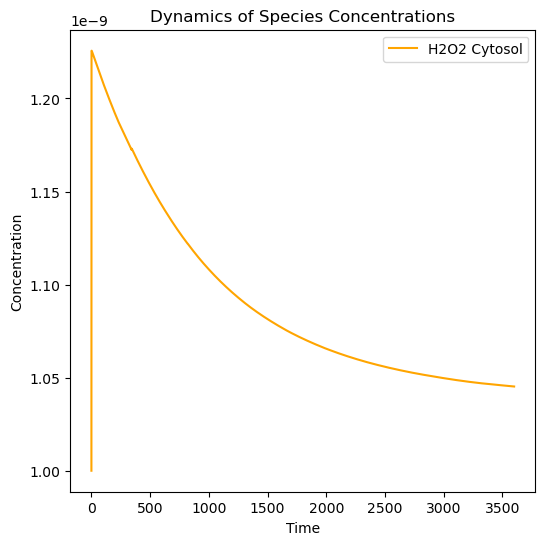

In [36]:
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# x0[0] = 2.019262743538677e-11 # H2O2media
# x0[1] = 5.204363434194223e-10 # H2O2cytosol
# #k[1] = 0 # intracellular peroxide production
# k[28] = 1e-5 # nox generation of superoxide
# #k[29] = 0 # superoxide dismutase reduction and oxidation by superoxide
# k[30] = 0 # intracellular superoxide production

t = np.linspace(0, 3600, 3601)
solution = odeint(model, x0, t, args=(k,))

# Replace odeint with solve_ivp
# solution = solve_ivp(lambda t, y: model(y, t, k), 
#                     [0, 120000], 
#                     x0, 
#                     method='Radau',  # Use Backward Differentiation Formula (good for stiff problems)
#                     t_eval=np.linspace(0, 120000, 10000))

# Plot the results
plt.figure(figsize=(6, 6))
for i in range(0, len(x0)): 
    # if i == 0:
    #     plt.plot(t, solution[:, i], label='H2O2 Media')
    if i == 1:
        plt.plot(t, solution[:, i], label='H2O2 Cytosol', color='orange')
    # elif i == 5:
    #     plt.plot(t, solution[:, i], label='GSH')
    # else:
    #     plt.plot(t, solution[:, i], label=f'x[{i}]')
# plt.plot(solution.t, solution.y[0, :], label='H2O2media')
# plt.plot(solution.t, solution.y[1, :], label='H2O2cytosol')
# plt.plot(solution.t, solution.y[24, :], label='superoxide media')
# plt.plot(solution.t, solution.y[25, :], label='superoxide cytosol')
# plt.plot(solution.t, solution.y[26, :], label='SOD reduced')
# plt.plot(solution.t, solution.y[27, :], label='SOD oxidized')

# plt.plot(t, solution[:, 0], label='H2O2media')
# plt.plot(t, solution[:, 1], label='H2O2cytosol')
# # plt.plot(t, solution[:, 22], label='NADPH')
# # plt.plot(t, solution[:, 23], label='NADP-')
# # plt.plot(t, solution[:, 26], label='SOD reduced')
# # plt.plot(t, solution[:, 27], label='SOD oxidized')
# print(solution[-1, 0])
print(solution[-1, 5])

plt.xlabel('Time')
plt.ylabel('Concentration')
plt.title('Dynamics of Species Concentrations')
plt.legend()
plt.show()

In [53]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# Setup
num_steps = 3600
dt = 1  # 1 second per step
t_span = [0, dt]  # Integration span for each step
t_full = np.linspace(0, num_steps, num_steps+1)
x_current = x0.copy()  # Start with initial conditions

# Storage for results
solution = np.zeros((num_steps+1, len(x0)))
solution[0, :] = x0  # Store initial conditions

# Step-by-step integration
for i in range(num_steps):
    # Integrate just one time step
    t_local = np.array([0, dt])
    x_step = odeint(model, x_current, t_local, args=(k,))
    
    # Update current state (take the final state from this step)
    x_current = x_step[-1, :].copy()
    
    # Store results
    solution[i+1, :] = x_current
    
    # Here you could modify x_current if needed
    # For example: x_current[0] += some_input_function(i)
    
    # Optional: Print progress occasionally
    if i % 360 == 0:
        print(f"Completed {i} of {num_steps} steps")

# Then plot as before
plt.figure(figsize=(15, 6))
for i in range(0, len(x0)):
    plt.plot(t_full, solution[:, i], label=f'x[{i}]')
plt.xlabel('Time')
plt.ylabel('Concentration')
plt.title('Step-by-step Integration')
plt.legend()
plt.show()

Completed 0 of 3600 steps
Completed 360 of 3600 steps
Completed 720 of 3600 steps


KeyboardInterrupt: 

In [ ]:
import numpy as np
from scipy.integrate import odeint

def blap_ODE_system(endtime, step, celldens, protein_abund, blap_conc, parameter_pctchange=None, species_pctchange=None):
    """
    Model for compartmentalized hydrogen peroxide consumption
    
    Parameters:
    -----------
    endtime : float
        End time for simulation
    step : float
        Maximum step size for solver
    celldens : float
        Cell density
    protein_abund : array-like
        Protein abundance values
    blap_conc : float
        B-lap concentration
    parameter_pctchange : array-like, optional
        Percentage changes for parameters
    species_pctchange : array-like, optional
        Percentage changes for species
    
    Returns:
    --------
    time_series : ndarray
        Array containing time points and state variables
    """
    
    # Establish genes of interest and index
    genes = ["GPX1", "GPX2", "GPX3", "GPX4", "GPX5", "GPX6", "GPX7", "GPX8", "PRDX1", "PRDX2",
             "PRDX2", "PRDX3", "PRDX6", "CAT", "TXN", "TXN2", "TXNRD1", "TXNRD2", "TXNRD3", "GLRX", 
             "GLRX2", "G6PD", "GLUD1", "GSR", "GSTP1", "POR", "NQO1", "SOD1", "SOD2", "SOD3", 
             "AQP3", "AQP8", "AQP9", "GCLC"]

    # Solver Parameters
    ti = 0  # start time
    tf = endtime  # stop time
    tspan = (ti, tf)
    
    # Define parameter values
    k = np.zeros(36)
    
    # Rxns (Cytosolic)
    
    # H2O2 Transport
    # Permeability constant (plasma membrane)
    # H2O2cyt -> H2O2out
    k[0] = 2e-4 * protein_abund[29] / 0.0302  # cm/s
    
    # Mitochondrial production of H2O2in
    k[1] = 4
    
    # GPx1_red reacting with H2O2in
    # H2O2cyt + GPX1r -> GPX1o ; EC 1.11.1.9
    # Updated 9/22 with Kassi Stein PLoS Comp Bio paper k2
    k[2] = 60  # uM-1*s-1 (60 uM-1*s-1 Kassi paper)
    
    # GPx1_ox reacting with GSH
    # GPX1o + GSH -> GPX1-SG
    # Updated 9/22 with KS PLoS Comp Bio paper k3
    k[3] = 0.04  # uM-1*s-1
    
    # GPx1-SG reacting with GSH
    # GPX1-SG + GSH -> GPX1r + GSSG
    # Updated 9/22 with KS PLoS Comp Bio Paper k4
    k[4] = 10  # uM-1*s-1
    
    # Catalase reacts with H2O2 inside peroxisome
    # H2O2p ->
    # Updated 10/6
    k[5] = 34  # uM-1*s-1
    
    # Km of NADP+
    # Updated 9/22 with KS PLoS Comp Bio Paper k4
    k[6] = 57  # uM
    
    # Peroxiredoxin is oxidized by H2O2
    # Updated 10/6
    k[7] = 40  # uM-1*s-1
    
    # Oxidized peroxiredoxin is over-oxidized by H2O2
    # Updated 10/6
    k[8] = 0.072  # uM-1*s-1
    
    # Reduction of overoxidized Prx by Srx enzyme
    k[9] = 3e-3  # s-1
    
    # Self-catalyzed disulfide formation of Prx-SS from Prx-SOH
    k[10] = 15  # s-1
    
    # Peroxiredoxin is reduced by Thioredoxin
    # Updated 10/6
    k[11] = 2.1  # uM-1*s-1
    
    # Auto-oxidation of GSH
    k[12] = 7.4e-05  # s-1
    
    # Protein monothiol oxidized by H2O2
    # Updated 10/6
    k[13] = 0.01  # uM-1*s-1
    
    # Oxidized Protein monothiol glutathionylated by GSH
    # Updated 10/6
    k[14] = 0.12  # uM-1*s-1
    
    # Grx-SH de-glutathionylates Protein-SSG
    # Updated 10/6
    k[15] = 0.091  # uM-1*s-1
    
    # GSH de-glutathionylates Grx-SSG
    # Updated 10/6
    k[16] = 0.037  # uM-1*s-1
    
    # Protein dithiol oxidized by H2O2
    # Updated 10/6
    k[17] = 5e-1  # uM-1*s-1
    
    # Protein disulfide reduced by Trx1
    # Updated 10/6
    k[18] = 1e-1  # uM-1*s-1
    
    # GSSG reduced by GR
    k[19] = 3.2 * protein_abund[22] / 0.1419  # uM-1*s-1
    
    # Oxidized Thioredoxin reduced by TrxR
    k[20] = 2e1 * protein_abund[15] / 0.1816  # uM-1*s-1
    
    # Production of NADPH by G6P-DH
    k[21] = 3.75e2 * (protein_abund[20] + protein_abund[21]) / (0.2581 + 0.5159)  # uM/s
    
    # Permeability constant (peroxisomal membrane)
    k[22] = 3e-3  # cm/s
    
    # GSH synthesis
    k[23] = 4.1e-1 * protein_abund[32] / .0075  # uM/s 4.1e-7
    
    # GSSG efflux
    k[24] = 1.2e-2  # uM/s 1.2e-8
    
    # GSH + GSSG efflux
    k[25] = 1.2e-1  # uM/s 1.2e-7
    
    # NQO1 Reaction; b-lap Q->HQ
    k[28] = 161.5 * protein_abund[25] / .2905  # 1/uM-s
    
    # b-lap HQ->SQ
    k[29] = 3e2  # 1/uM-s
    
    # b-lap SQ->Q
    k[30] = 3e2  # 1/uM-s
    
    # SOD
    k[31] = 6400.0 * protein_abund[26] / 1.6641  # 1/uM-s
    
    # CPR
    k[32] = 1900 * protein_abund[24] / 0.2231  # 1/uM-s
    
    # blap perm
    k[33] = 1e-6  # cm/s
    
    # blapHQ + GSH -> blapHQ-SG
    k[34] = 0.05 * protein_abund[23] / 2.6052  # 1/uM-s
    
    # blapHQ-SG -> blapHQ-SG extracell
    k[35] = 1e-6  # cm/s
    
    if parameter_pctchange is not None:
        k = k * parameter_pctchange
    
    # Defining initial Conditions (Concentrations in uM = micromoles/Liter)
    # Defining the array, x0, that will house initial concentrations
    x0 = np.zeros(32)
    
    # H2O2media
    x0[0] = 0.0
    
    # H2O2cytosol
    x0[1] = 1.0e-3
    
    # GPXr
    x0[2] = protein_abund[0]
    
    # GPXo
    x0[3] = x0[2] / 5e9
    
    # GPX-SG
    x0[4] = x0[2] / 5e9
    
    # GSH
    x0[5] = 368
    
    # GSSG
    x0[6] = x0[5] / 206
    
    # Catalase
    x0[7] = protein_abund[12]
    
    # H2O2peroxisome
    x0[8] = 1.0e-10
    
    # Prx1/2-SH
    x0[9] = protein_abund[8] + protein_abund[9]
    
    # Prx1/2-SOH
    x0[10] = x0[9] / 1.92e9
    
    # Prx1/2-SOOH
    x0[11] = x0[9] / 1.92e9
    
    # Prx1/2-SS
    x0[12] = x0[9] * (.5 / 100)
    
    # Trx1-SH
    x0[13] = protein_abund[13]
    
    # Trx1-SS
    x0[14] = x0[13] / 5.7
    
    # Pr-SH
    x0[15] = 50  # 1.22e2
    
    # Pr-SOH
    x0[16] = x0[15] * (.5 / 100)
    
    # Pr-SSG
    x0[17] = x0[15] * (.5 / 100)
    
    # Grx-SH
    x0[18] = protein_abund[18]
    
    # Grx-SSG
    x0[19] = x0[18] * (.5 / 100)
    
    # Pr-(SH)2
    x0[20] = 450
    
    # Pr-SS
    x0[21] = x0[20] * (.5 / 100)
    
    # NADPH
    x0[22] = 3.0e1
    
    # NADP+
    x0[23] = x0[22] / 100
    
    # blap Q
    x0[24] = 0
    
    # blap HQ
    x0[25] = 0
    
    # blap SQ
    x0[26] = 0
    
    # superO2
    x0[27] = 0
    
    # oxygen
    x0[28] = 2.6e2
    
    # blap extracell
    x0[29] = blap_conc
    
    # blap-GSH
    x0[30] = 0
    
    # blap-GSH extracell
    x0[31] = 0
    
    if species_pctchange is not None:
        x0 = x0 * species_pctchange
        
    x0[3] = x0[2] / 5e9  # GPXo
    x0[4] = x0[2] / 5e9  # GPX-SG
    x0[6] = x0[5] / 206  # GSSG
    x0[10] = x0[9] / 1.92e9  # Prx-SOH
    x0[11] = x0[9] / 1.92e9  # Prx-SOOH
    x0[12] = x0[9] * (.5 / 100)  # Prx-SS
    x0[14] = x0[13] / 5.7  # Trx1-SS
    x0[16] = x0[15] * (.5 / 100)  # Pr-SOH
    x0[17] = x0[15] * (.5 / 100)  # Pr-SSG
    x0[19] = x0[18] * (.5 / 100)  # Grx-SSG
    x0[21] = x0[20] * (.5 / 100)  # Pr-SS
    x0[23] = x0[22] / 100  # NADP+
    
    def ode_sys(t, x, k, celldens):
        # Apply bounds to state variables to prevent them from going too high/low
        dxdt = np.zeros_like(x)
        
        x_area = celldens * 1 * 1000 * 4 * np.pi * .00001**2  # in cm^2
        c_area = celldens * 1 * 4 * np.pi * .001**2 - x_area  # in cm^2
        x_vol = celldens * 1 * 1000 * 4/3 * np.pi * .00001**3  # in cm^3
        c_vol = celldens * 1 * 4/3 * np.pi * .001**3 - x_vol  # in cm^3
        m_vol = 1000 - x_vol - c_vol  # in cm^3
        
        # Cytosolic Dynamics
        dxdt[0] = k[0] * c_area * (x[1] - x[0]) / m_vol  # H2O2 extracellular
        
        dxdt[1] = (k[0] * c_area * (x[0] - x[1]) / c_vol - 
                  k[22] * x_area * (x[1] - x[8]) / c_vol + 
                  k[1] - k[2] * x[2] * (x[1] - x0[1]) - 
                  k[7] * x[9] * (x[1] - x0[1]) - k[8] * x[10] * (x[1] - x0[1]) - 
                  k[13] * x[15] * (x[1] - x0[1]) - k[17] * x[20] * (x[1] - x0[1]) + 
                  k[31] * x[27]**2)  # H2O2 cytosol
        
        dxdt[2] = -k[2] * x[2] * (x[1] - x0[1]) + k[4] * (x[4] - x0[4]) * x[5]  # GPXr
        
        dxdt[3] = k[2] * x[2] * (x[1] - x0[1]) - k[3] * (x[3] - x0[3]) * x[5]  # GPXo
        
        dxdt[4] = k[3] * (x[3] - x0[3]) * x[5] - k[4] * (x[4] - x0[4]) * x[5]  # GPX-SG
        
        dxdt[5] = (-k[3] * (x[3] - x0[3]) * x[5] - 
                  k[4] * (x[4] - x0[4]) * x[5] - 
                  2 * k[12] * x[5] - k[14] * (x[16] - x0[16]) * x[5] - 
                  k[34] * x[25] * x[5] - k[16] * (x[19] - x0[19]) * x[5] + 
                  2 * k[19] * (x[6] - x0[6]) * x[22] + 
                  k[23] - k[25] * x[5] * x[6])  # GSH
        
        dxdt[6] = (k[4] * (x[4] - x0[4]) * x[5] + k[12] * x[5] + 
                  k[16] * (x[19] - x0[19]) * x[5] - 
                  k[19] * (x[6] - x0[6]) * x[22] - 
                  k[24] - k[25] * x[5] * x[6])  # GSSG
        
        dxdt[7] = 0  # FeCat
        
        dxdt[8] = k[22] * x_area * (x[1] - x[8]) / x_vol - k[5] * x[7] * (x[8] - x0[8])  # H2O2 peroxisome
        
        dxdt[9] = -k[7] * x[9] * (x[1] - x0[1]) + k[11] * (x[12] - x0[12]) * x[13]  # Prx-SH
        
        dxdt[10] = (k[7] * x[9] * (x[1] - x0[1]) - k[8] * x[10] * (x[1] - x0[1]) + 
                   k[9] * (x[11] - x0[11]) - k[10] * x[10])  # Prx-SOH
        
        dxdt[11] = k[8] * x[10] * (x[1] - x0[1]) - k[9] * (x[11] - x0[11])  # Prx-SOOH
        
        dxdt[12] = k[10] * x[10] - k[11] * (x[12] - x0[12]) * x[13]  # Prx-SS
        
        dxdt[13] = (-k[11] * (x[12] - x0[12]) * x[13] - 
                   k[18] * (x[21] - x0[21]) * x[13] + 
                   k[20] * (x[14] - x0[14]) * x[22])  # Trx-SH
        
        dxdt[14] = (k[11] * (x[12] - x0[12]) * x[13] + 
                   k[18] * (x[21] - x0[21]) * x[13] - 
                   k[20] * (x[14] - x0[14]) * x[22])  # Trx-SS
        
        dxdt[15] = -k[13] * x[15] * (x[1] - x0[1]) + k[15] * x[18] * (x[17] - x0[17])  # Pr-SH
        
        dxdt[16] = k[13] * x[15] * (x[1] - x0[1]) - k[14] * (x[16] - x0[16]) * x[5]  # Pr-SOH
        
        dxdt[17] = k[14] * (x[16] - x0[16]) * x[5] - k[15] * x[18] * (x[17] - x0[17])  # Pr-SSG
        
        dxdt[18] = k[16] * (x[19] - x0[19]) * x[5] - k[15] * x[18] * (x[17] - x0[17])  # Grx-SH
        
        dxdt[19] = k[15] * x[18] * (x[17] - x0[17]) - k[16] * (x[19] - x0[19]) * x[5]  # Grx-SSG
        
        dxdt[20] = -k[17] * x[20] * (x[1] - x0[1]) + k[18] * (x[21] - x0[21]) * x[13]  # Pr-(SH)2
        
        dxdt[21] = k[17] * x[20] * (x[1] - x0[1]) - k[18] * (x[21] - x0[21]) * x[13]  # Pr-SS
        
        dxdt[22] = (-k[19] * (x[6] - x0[6]) * x[22] - 
                   k[20] * (x[14] - x0[14]) * x[22] - 
                   k[28] * x[24] * x[22] + 
                   k[21] * (x[23] - x0[23]) / (k[6] + x[23]))  # NADPH
        
        dxdt[23] = (k[19] * (x[6] - x0[6]) * x[22] + 
                   k[20] * (x[14] - x0[14]) * x[22] + 
                   k[28] * x[24] * x[22] - 
                   k[21] * (x[23] - x0[23]) / (k[6] + x[23]))  # NADP+
        
        dxdt[24] = (k[33] * c_area * (x[29] - x[24]) / c_vol + 
                   k[30] * x[26] * x[28] - k[28] * x[24] * x[22] - 
                   k[32] * x[24] * x[22])  # b-lap Q cyto
        
        dxdt[25] = (k[28] * x[24] * x[22] - k[29] * x[25] * x[28] - 
                   k[34] * x[25] * x[5] + k[32] * x[26] * x[22])  # b-lap HQ
        
        dxdt[26] = (k[29] * x[25] * x[28] - k[30] * x[26] * x[28] + 
                   k[32] * x[24] * x[22] - k[32] * x[26] * x[22])  # b-lap SQ
        
        dxdt[27] = k[29] * x[25] * x[28] + k[30] * x[26] * x[28] - k[31] * x[27]**2  # superO2
        
        dxdt[28] = -k[29] * x[25] * x[28] - k[30] * x[26] * x[28] + k[31] * x[27]**2  # O2
        
        dxdt[29] = -k[33] * (x[29] - x[24]) / m_vol  # b-lap Q extracellular
        
        dxdt[30] = k[34] * x[25] * x[5] - k[35] * c_area * (x[30] - x[31]) / c_vol  # b-lapHQ-GSH
        
        dxdt[31] = k[35] * c_area * (x[30] - x[31]) / m_vol  # b-lapHQ-GSH extracellular
        
        return dxdt
    
    # Integrate the ODE system
    atol = 1e-10
    rtol = 1e-4
    sol = solve_ivp(lambda t, x: ode_sys(t, x0, k, celldens), tspan, x0, 
                #method='BDF',
                atol=atol, rtol=rtol, max_step=step)
    
    # Combine time and state into a single array
    time_series = np.column_stack((sol.t, sol.y.T))
    
    return time_series

In [ ]:
import pandas as pd
import os 
from scipy.integrate import solve_bvp
import numpy as np
        
print("Loading gene expression data...")

# Define genes of interest
genes_of_interest = [
    "GPX1", "GPX2", "GPX3", "GPX4", "GPX5", "GPX6", "GPX7", "GPX8",
    "PRDX1", "PRDX2", "PRDX3", "PRDX6", "CAT", "TXN", "TXN2", "TXNRD1", "TXNRD2", "TXNRD3",
    "GLRX", "GLRX2", "G6PD", "GLUD1", "GSR", "GSTP1", "POR", "NQO1", "SOD1", "SOD2", "SOD3",
    "AQP3", "AQP8", "AQP9", "GCLC"
]

# Load metadata
metadata_file = os.path.join(os.getcwd(), "2021-06-08_scrnaseqdata.csv")
metadata = pd.read_csv(metadata_file)

# Directory with expression data
files = os.path.join(os.getcwd(), "HNSCC_Broad_scRNAseq")

gene_index = []
# Load first cell data to get gene indices
first_cell_file = os.path.join(files, f"{metadata['cell'].iloc[0]}.csv")
protein = pd.read_csv(first_cell_file)

# Find the index of each gene of interest in the protein table
for gene in genes_of_interest:
    # Find indices where the first column matches the gene name
    # Note: In pandas, we use boolean indexing instead of MATLAB's find()
    matches = protein.iloc[:, 0] == gene
    indices = matches[matches].index.tolist()
    gene_index.extend(indices)

protein_vals = np.zeros((33, len(metadata)))
# Loop through each cell in the metadata
for i in range(len(metadata)):
    # Load the protein data for this cell
    cell_file = os.path.join(files, f"{metadata['cell'].iloc[i]}.csv")
    protein = pd.read_csv(cell_file)
    # Extract expression values for genes of interest and store in protein_vals
    # We use gene_index to select rows and column index 1 for values
    protein_vals[:, i] = protein.iloc[gene_index, 1].values

# Convert from PPM to micromolar
protein_vals = protein_vals * 5.29e-4
protein_averages = np.mean(protein_vals, axis=1)

Loading gene expression data...


In [ ]:
import time
import warnings 
from scipy.integrate import solve_ivp

# Set up parameters
endtimes = 3600  # Same as in MATLAB
timestep = 1
cell_density = 1.0e9
p_change = None  # Parameter change, adapt as needed
x_change = None  # Species change, adapt as needed
blap_conc = 3    # b-lap concentration

# Initialize results array
num_simulations = protein_vals.shape[1]
# Assuming your ODE returns 31 state variables + 1 time column
results_blap = np.zeros((33, num_simulations))  
warning_sims = []

# Start timing
start_time = time.time()

# Create a context manager to catch warnings 
with warnings.catch_warnings(record=True) as w:
    # Run simulations
    for sim in range(num_simulations):
        if sim % 50 == 0:
            print(f"Running simulation {sim}")
            print(f"Elapsed time: {time.time() - start_time:.2f} seconds")
        
        # Reset warnings for this iteration
        w.clear()
        if sim == 1:
            print(protein_vals[:,sim])
        try:
            # Call the ODE solver with appropriate protein values for this simulation
            y_blap = blap_ODE_system(endtimes, timestep, cell_density, 
                                     protein_vals[:, sim], blap_conc, 0.0, 0.0)
            print(y_blap[-1,1:])
            # Check if there were any warnings
            if len(w) == 0:
                # Store last time point values (equivalent to y_blap(end,2:end))
                results_blap[:, sim] = y_blap[-1, 1:]
            else:
                warning_sims.append(sim)
                print(f"Warning in simulation {sim}: {w[-1].message}")
        
        except Exception as e:
            # Handle any exceptions 
            warning_sims.append(sim)
            print(f"Error in simulation {sim}: {str(e)}")

print(f"Total time: {time.time() - start_time:.2f} seconds")
print(f"Simulations with warnings/errors: {len(warning_sims)}/{num_simulations}")

# Convert warning_sims to numpy array if needed
warning_sims = np.array(warning_sims)

# Now results_blap contains the final state of each successful simulation
# and warning_sims contains indices of simulations that had warnings

Running simulation 0
Elapsed time: 0.00 seconds
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0.]
Warning in simulation 0: invalid value encountered in scalar divide
[6.22221506e-03 8.60246310e-04 2.64141576e-02 1.44732990e-01
 4.19650055e-04 1.06346099e-03 1.86672399e-01 2.26192712e-04
 9.15432588e+00 1.39598397e+01 2.17720936e-01 5.44444800e-01
 1.68799198e-02 1.14636255e+00 4.68985699e-03 1.20087718e-02
 1.32200272e-02 3.62347802e-04 5.73589254e-01 7.76102596e-04
 5.34870627e-03 4.05767964e-03 3.85974123e-03 2.75683425e+00
 1.49331131e-02 1.10351242e-02 2.17159269e+00 1.69603598e-01
 6.40511335e-02 6.85435809e-04 4.22128147e-05 3.52450746e-04
 4.19917015e-03]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0.]
Error in simulation 1: could not broadcast input array from shape (32,) into shape (33,)
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 

KeyboardInterrupt: 